# STA 556 — Homework 4
## Simulation & Resampling
## Samuel Anoff Addo

IMPORTING LIBRARIES, SETTING SEED AND CREATING RANDOM GENERATOR

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


SEED = 556
rng = np.random.default_rng(SEED)

In [2]:
SEED = 556

# Random Generator 
rng = np.random.default_rng(SEED)

PART ONE - MONTE CARLO PROBABILITY

TASK: Estimate one probability by simulation with at least 10,000 draws, report it, compare it with the true value, and explain Monte Carlo error.

In [3]:
## Estimating Probability that a standard Normal random variable exceeds 1.645
##P(Z > 1.645).

M = 100_000
z = rng.normal(loc = 0, scale = 1, size = M)
indicator = (z > 1.645) 
p_hat = indicator.mean()

In [4]:
print(f"Estimated Probability : {p_hat:.5f}")


Estimated Probability : 0.05015


In [5]:
## Monte Carlo standard error
g = indicator.astype(int)                      # 0/1 values
mcse = g.std(ddof=1) / np.sqrt(len(g))

In [6]:
print(f"MCSE  : {mcse:.5f}")

MCSE  : 0.00069


In [7]:
## Comparing With Available Theoretical Value
Prob_True = stats.norm.sf(1.645)


In [8]:
print(f"Exact value    : {Prob_True:.5f}")
print(f"Absolute error : {abs(p_hat - Prob_True):.5f}")

Exact value    : 0.04998
Absolute error : 0.00017


PART ONE:

Simulations used: 100,000.

Estimate: An estimate of P(Z > 1.645), where Z ~ Normal(0, 1), by simulation. This is the area under the standard normal curve to the right of 1.645.

Comparison With Theory: The exact value from `scipy.stats.norm.sf(1.645)` is `0.04998`. My estimate differs by `0.00017`, with a Monte Carlo Standard Error of `0.00069`. 

**Result.**

| Quantity | Value |
|---|---|
| Monte Carlo estimate | 0.05015 |
| Monte Carlo standard error | 0.00069 |
| Exact value, `scipy.stats.norm.sf(1.645)` | 0.04998 |
| Absolute error | 0.00017 |


**Monte Carlo error.** The estimate is itself random because it is based on a finite number of random draws; a different seed would give a slightly different value. The Monte Carlo standard error is computed as the sample standard deviation of the simulated 0s and 1s values divided by the square root of M. It measures the uncertainty in the estimate caused by using a finite number of simulations. It shrinks roughly like 1/sqrt(M) thus one divided by square root of M, so reducing the error by a factor of 10 requires about 100 times as many simulations.

PART TWO — MONTE CARLO STABILITY

TASK: Repeat your Part 1 estimate at several simulation sizes, show a table or plot of how the estimate stabilizes, and explain why more simulations help.

In [9]:
## Simulation Sizes

sizes = [100, 1_000, 10_000, 100_000]
p_true = stats.norm.sf(1.645)

In [10]:
MonteCarlo = []
for m in sizes:
    z = rng.normal(loc=0, scale=1, size=m)
    g = (z > 1.645).astype(int)

    estimate = g.mean()
    mcse = g.std(ddof=1) / np.sqrt(len(g))

    MonteCarlo.append({
        "Simulation_Size": m,
        "Estimate": estimate,
        "MCSE": mcse,
        "Absolute_Error": abs(estimate - p_true),
    })

In [11]:
MonteCarlo_df = pd.DataFrame(MonteCarlo)
print(f"Exact value: {p_true:.5f}")
MonteCarlo_df

Exact value: 0.04998


,Simulation_Size,Estimate,MCSE,Absolute_Error
0,100,0.05000,0.021904,0.000015
1,1000,0.04900,0.006830,0.000985
2,10000,0.05460,0.002272,0.004615
3,100000,0.04855,0.000680,0.001435


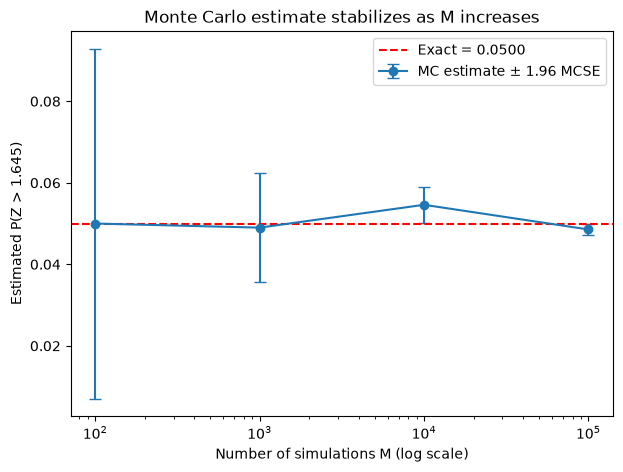

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(MonteCarlo_df["Simulation_Size"], MonteCarlo_df["Estimate"],
            yerr=1.96 * MonteCarlo_df["MCSE"],
            fmt="o-", capsize=4, label="MC estimate ± 1.96 MCSE")
ax.axhline(p_true, color="red", linestyle="--", label=f"Exact = {p_true:.4f}")

ax.set_xscale("log")
ax.set_xlabel("Number of simulations M (log scale)")
ax.set_ylabel("Estimated P(Z > 1.645)")
ax.set_title("Monte Carlo estimate stabilizes as M increases")
ax.legend()
plt.show()

PART TWO:

Results: A repeated estimate of P(Z > 1.645) using M = 100, 1,000, 10,000, and 100,000 simulations. The estimates were 0.05000, 0.04900, 0.05460, and 0.04855, compared with the exact value of 0.04998. The Monte Carlo standard error fell from ___ to ___.

Why More Simulations Help: Increasing the number of simulations improves the reliability of Monte Carlo estimates because it reduces random variation in the results.According to the Law of Large Numbers, as the number of simulations (\(M\)) increases, the sample average tends to get closer to the true expected value.


The Monte Carlo estimate is an average of simulated values, so its error comes from random variation in the draws. Averaging over more draws cancels more of that variation, and the standard error shrinks roughly by 1/sqrt(M). Reducing the error by a factor of 10 therefore requires about 100 times as many simulations.




**Why increasing the number of simulations helps.** The estimate is an average of simulated 0/1 values, so its error comes from random variation in which draws happen to fall in the tail. Averaging over more draws cancels more of that variation, so the standard error shrinks like 1/√M. This gives a trade-off: halving the error requires four times as many simulations, and reducing it tenfold requires about 100 times as many.